# Computational Modeling of CBDA Biosynthesis in *Saccharomyces cerevisiae*

This notebook implements the heterologous biosynthetic pathway for cannabidiolic acid (CBDA) in the genome-scale metabolic model iMM904 of *Saccharomyces cerevisiae*.

The workflow includes:

1. Import and validation of the iMM904 model.
2. Inspection of native metabolites.
3. Addition of heterologous metabolites.
4. Implementation of the synthetic pathway.
5. Mass balance verification.
6. Flux Balance Analysis (FBA).
7. Sensitivity analyses under different environmental conditions.

**Author:** Luca Nalini Bortolato D'Alessandro

**Institution:** Instituto Federal de Educação, Ciência e Tecnologia de São Paulo (IFSP)

**Project:** Institutional Scientific Initiation

# 1. Importing libraries

In [7]:
from pathlib import Path
import cobra

# 2. Loading the genome-scale metabolic model

The iMM904 model is loaded in JSON format and its dimensions are verified before any modifications are introduced.

In [8]:
from pathlib import Path
import cobra

MODEL_PATH = Path("models/iMM904.json")

modelo = cobra.io.load_json_model(MODEL_PATH)

# 3. Initial model validation

The integrity of the imported model is verified by checking the number of reactions, metabolites and genes.

In [9]:
# Validate model dimensions
print(f"Model ID: {modelo.id}")
print(f"Number of reactions: {len(modelo.reactions)}")
print(f"Number of metabolites: {len(modelo.metabolites)}")
print(f"Number of genes: {len(modelo.genes)}")

Model ID: iMM904
Number of reactions: 1577
Number of metabolites: 1226
Number of genes: 905


# 4. Inspection of native metabolites

Before implementing the heterologous pathway, the model is screened to identify native metabolites that can be reused. This step avoids unnecessary duplication and ensures compatibility between the added reactions and the existing metabolic network.

In [10]:
# Busca ampliada por fragmentos de nomes
termos_chave = ["coa", "pyrophosphate", "diphosphate", "hexanoate"]

print("Metabólitos encontrados:")

for termo in termos_chave:
    print(f"\n--- Verificando termo: {termo} ---")
    for met in modelo.metabolites:
        if termo in met.name.lower():
            print(f"ID: {met.id} | Nome: {met.name}")

Metabólitos encontrados:

--- Verificando termo: coa ---
ID: 4hbzcoa_m | Nome: 4 hydroxybenoyl CoA C28H36N7O18P3S
ID: 3hdcoa_x | Nome: (S)-3-Hydroxydecanoyl-CoA
ID: 3hddcoa_x | Nome: (S)-3-Hydroxydodecanoyl-CoA
ID: 3hhdcoa_x | Nome: (S)-3-Hydroxyhexadecanoyl-CoA
ID: 3hodcoa_x | Nome: (S)-3-Hydroxyoctadecanoyl-CoA
ID: 3htdcoa_x | Nome: (S)-3-Hydroxytetradecanoyl-CoA
ID: 3hxccoa_x | Nome:  S  3 Hydroxyhexacosyl CoA C47H82N7O18P3S
ID: 3odcoa_x | Nome: 3-Oxodecanoyl-CoA
ID: 3oddcoa_x | Nome: 3-Oxododecanoyl-CoA
ID: 3ohdcoa_x | Nome: 3-Oxohexadecanoyl-CoA
ID: 3ohodcoa_x | Nome: 3-Oxooctadecanoyl-CoA
ID: 3ohxccoa_x | Nome: 3 Oxohexacosyl CoA C47H80N7O18P3S
ID: 3otdcoa_x | Nome: 3-Oxotetradecanoyl-CoA
ID: aacoa_c | Nome: Acetoacetyl-CoA
ID: aacoa_m | Nome: Acetoacetyl-CoA
ID: accoa_c | Nome: Acetyl-CoA
ID: accoa_m | Nome: Acetyl-CoA
ID: accoa_n | Nome: Acetyl-CoA
ID: accoa_x | Nome: Acetyl-CoA
ID: dcacoa_c | Nome: Decanoyl-CoA (n-C10:0CoA)
ID: dcacoa_x | Nome: Decanoyl-CoA (n-C10:0CoA)
ID: dd

# 5. Addition of heterologous metabolites

Metabolites absent from the original iMM904 reconstruction were added to represent intermediates of the engineered pathway leading to CBDA biosynthesis.

In [11]:
from cobra import Metabolite

# É necessário definir cada objeto individualmente antes de usá-los na lista
# Intermediários do Ciclo C4
m1 = Metabolite('3hbutcoa_c', name='3-Hydroxybutyryl-CoA', formula='C25H42N7O18P3S', compartment='c')
m2 = Metabolite('crotcoa_c', name='Crotonyl-CoA', formula='C25H40N7O17P3S', compartment='c')

# Intermediários do Ciclo C6
m3 = Metabolite('3ohexcoa_c', name='3-keto-hexanoyl-CoA', formula='C27H44N7O18P3S', compartment='c')
m4 = Metabolite('3hhexcoa_c', name='3-hydroxyhexanoyl-CoA', formula='C27H46N7O18P3S', compartment='c')
m5 = Metabolite('t2hexcoa_c', name='trans-2-hexenoyl-CoA', formula='C27H44N7O17P3S', compartment='c')
m6 = Metabolite('hexcoa_c', name='Hexanoyl-CoA', formula='C27H46N7O17P3S', compartment='c')

# Intermediários e Produtos da Cannabis
m7 = Metabolite('olivetolate_c', name='Olivetolic acid', formula='C12H16O4', compartment='c')
m8 = Metabolite('cbga_c', name='Cannabigerolic acid', formula='C22H32O4', compartment='c')
m9 = Metabolite('cbda_c', name='Cannabidiolic acid', formula='C22H30O4', compartment='c')

# Agora que m1 até m9 existem, podemos adicioná-los ao modelo
modelo.add_metabolites([m1, m2, m3, m4, m5, m6, m7, m8, m9])

print("Sucesso! Todos os objetos foram criados e reconhecidos pelo modelo.")

Sucesso! Todos os objetos foram criados e reconhecidos pelo modelo.


## 5.1 Additional pathway intermediates

In [12]:
from cobra import Metabolite

# Additional intermediate required for the engineered hexanoyl-CoA pathway
m_but = Metabolite(
    id='butcoa_c',
    name='Butyryl-CoA',
    formula='C25H42N7O17P3S',
    compartment='c'
)

modelo.add_metabolites([m_but])

print(f"Metabolite {m_but.id} successfully added.")

Metabolite butcoa_c successfully added.


# 6. Implementation of the heterologous pathway

## 6.1 Clostridium module

Implementation of the reactions catalyzed by thiolase (ThlA), 3-hydroxyacyl-CoA dehydrogenase (Hbd) and crotonase (Crt), responsible for chain elongation toward hexanoyl-CoA.

In [13]:
from cobra import Reaction

# --- MÓDULO CLOSTRIDIUM (ThlA, Hbd, Crt) ---

# 1. Tiolase (thlA) - Ciclo C4 e C6
r_thl_c4 = Reaction('THL_c4')
r_thl_c4.name = 'Thiolase (thlA) - C4 cycle'
r_thl_c4.add_metabolites({
    modelo.metabolites.accoa_c: -2, 
    modelo.metabolites.get_by_id('aacoa_c'): 1, 
    modelo.metabolites.coa_c: 1
})

r_thl_c6 = Reaction('THL_c6')
r_thl_c6.name = 'Thiolase (thlA) - C6 cycle'
r_thl_c6.add_metabolites({
    modelo.metabolites.get_by_id('butcoa_c'): -1, 
    modelo.metabolites.accoa_c: -1, 
    modelo.metabolites.get_by_id('3ohexcoa_c'): 1, 
    modelo.metabolites.coa_c: 1
})

# 2. 3-Hidroxiacil-CoA Desidrogenase (hbd)
r_hbd_c4 = Reaction('HBD_c4')
r_hbd_c4.add_metabolites({
    modelo.metabolites.get_by_id('aacoa_c'): -1, 
    modelo.metabolites.nadh_c: -1, 
    modelo.metabolites.h_c: -1, 
    modelo.metabolites.get_by_id('3hbutcoa_c'): 1, 
    modelo.metabolites.nad_c: 1
})

r_hbd_c6 = Reaction('HBD_c6')
r_hbd_c6.add_metabolites({
    modelo.metabolites.get_by_id('3ohexcoa_c'): -1, 
    modelo.metabolites.nadh_c: -1, 
    modelo.metabolites.h_c: -1, 
    modelo.metabolites.get_by_id('3hhexcoa_c'): 1, 
    modelo.metabolites.nad_c: 1
})

# 3. Crotonase (crt)
r_crt_c4 = Reaction('CRT_c4')
r_crt_c4.add_metabolites({
    modelo.metabolites.get_by_id('3hbutcoa_c'): -1, 
    modelo.metabolites.get_by_id('crotcoa_c'): 1, 
    modelo.metabolites.h2o_c: 1
})

r_crt_c6 = Reaction('CRT_c6')
r_crt_c6.add_metabolites({
    modelo.metabolites.get_by_id('3hhexcoa_c'): -1, 
    modelo.metabolites.get_by_id('t2hexcoa_c'): 1, 
    modelo.metabolites.h2o_c: 1
})

modelo.add_reactions([r_thl_c4, r_thl_c6, r_hbd_c4, r_hbd_c6, r_crt_c4, r_crt_c6])
    

## 6.2 Euglena module

Implementation of trans-enoyl-CoA reductase (Ter), enabling reduction of trans-2-enoyl-CoA intermediates.

In [14]:
# --- MÓDULO EUGLENA (Ter) ---

r_ter_c4 = Reaction('TER_c4')
r_ter_c4.add_metabolites({
    modelo.metabolites.get_by_id('crotcoa_c'): -1, 
    modelo.metabolites.nadh_c: -1, 
    modelo.metabolites.h_c: -1, 
    modelo.metabolites.get_by_id('butcoa_c'): 1, 
    modelo.metabolites.nad_c: 1
})

r_ter_c6 = Reaction('TER_c6')
r_ter_c6.add_metabolites({
    modelo.metabolites.get_by_id('t2hexcoa_c'): -1, 
    modelo.metabolites.nadh_c: -1, 
    modelo.metabolites.h_c: -1, 
    modelo.metabolites.get_by_id('hexcoa_c'): 1, 
    modelo.metabolites.nad_c: 1
})

modelo.add_reactions([r_ter_c4, r_ter_c6])

In [15]:
# Busca metabólitos que contenham "geranyl" no nome ou ID
for met in modelo.metabolites:
    if "geranyl" in met.name.lower() or "grpp" in met.id.lower():
        print(f"ID: {met.id} | Nome: {met.name}")
        

ID: grdp_c | Nome: Geranyl diphosphate
ID: ggdp_c | Nome: Geranylgeranyl diphosphate C20H33O7P2


## 6.3 Cannabis pathway

Implementation of the heterologous biosynthetic reactions catalyzed by TKS/OAC, CBGAS and CBDAS, leading to CBDA production.

In [16]:
from cobra import Reaction

# --- MÓDULO CANNABIS (TKS, OAC, CBGAS, CBDAS) ---

# 5. Complexo TKS/OAC: Produção de Ácido Olivetólico
r_ols_oac = Reaction('OLS_OAC')
r_ols_oac.add_metabolites({
    modelo.metabolites.get_by_id('hexcoa_c'): -1,
    modelo.metabolites.malcoa_c: -3, # Verifique se o ID é este mesmo ou 'malcoa_c'
    modelo.metabolites.get_by_id('olivetolate_c'): 1,
    modelo.metabolites.co2_c: 3,
    modelo.metabolites.coa_c: 4
})

# 6. CBGA Sintase (CBGAS): Prenilação
# Aqui usamos o ID 'grdp_c' que você encontrou!
r_cbgas = Reaction('CBGAS')
r_cbgas.add_metabolites({
    modelo.metabolites.get_by_id('olivetolate_c'): -1,
    modelo.metabolites.get_by_id('grdp_c'): -1, 
    modelo.metabolites.get_by_id('cbga_c'): 1,
    modelo.metabolites.ppi_c: 1
})

# 7. CBDA Sintase (CBDAS): Ciclização Oxidativa
r_cbdas = Reaction('CBDAS')
r_cbdas.add_metabolites({
    modelo.metabolites.get_by_id('cbga_c'): -1,
    modelo.metabolites.o2_c: -1,
    modelo.metabolites.get_by_id('cbda_c'): 1,
    modelo.metabolites.h2o2_c: 1
})

modelo.add_reactions([r_ols_oac, r_cbgas, r_cbdas])
print("Via final conectada com o ID grdp_c!")

Via final conectada com o ID grdp_c!


In [17]:
# Verifica se as novas reações estão balanceadas
for rxn_id in ['THL_c4', 'THL_c6', 'TER_c4', 'TER_c6', 'OLS_OAC', 'CBGAS', 'CBDAS']:
    rxn = modelo.reactions.get_by_id(rxn_id)
    check = rxn.check_mass_balance()
    if check:
        print(f"Atenção na reação {rxn_id}: {check}")
    else:
        print(f"Reação {rxn_id} balanceada perfeitamente.")

Reação THL_c4 balanceada perfeitamente.
Reação THL_c6 balanceada perfeitamente.
Reação TER_c4 balanceada perfeitamente.
Reação TER_c6 balanceada perfeitamente.
Atenção na reação OLS_OAC: {'H': -1, 'charge': -1}
Reação CBGAS balanceada perfeitamente.
Reação CBDAS balanceada perfeitamente.


In [18]:
# Cria uma reação de demanda (Sink) para o CBDA
# Isso simula a secreção ou acúmulo do produto final
modelo.add_boundary(modelo.metabolites.get_by_id('cbda_c'), type='demand', reaction_id='DM_cbda_c')

# Define a produção de CBDA como a função objetivo
modelo.objective = 'DM_cbda_c'

In [19]:
solucao = modelo.optimize()

print(f"Status da Simulação: {solucao.status}")
print(f"Taxa de produção de CBDA: {solucao.objective_value:.4f} mmol/gDCW.h")

Status da Simulação: optimal
Taxa de produção de CBDA: 0.7885 mmol/gDCW.h


# 8. Sensitivity analysis

This section evaluates the influence of glucose uptake and oxygen availability on the predicted production of cannabidiolic acid (CBDA) using Flux Balance Analysis.

In [20]:
import matplotlib.pyplot as plt

glucose_rates = []
cbda_fluxes = []

for glucose in range(1, 21):

    with modelo:

        modelo.reactions.EX_glc__D_e.lower_bound = -glucose

        solucao = modelo.optimize()

        glucose_rates.append(glucose)
        cbda_fluxes.append(solucao.objective_value)

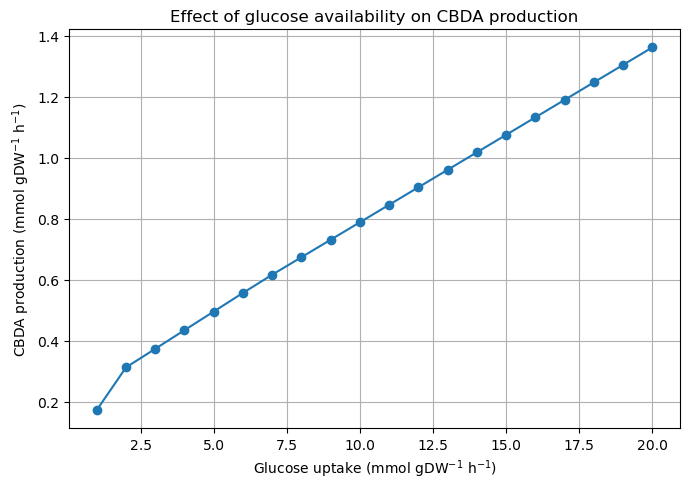

In [21]:
plt.figure(figsize=(7,5))

plt.plot(glucose_rates, cbda_fluxes, marker='o')

plt.xlabel("Glucose uptake (mmol gDW$^{-1}$ h$^{-1}$)")
plt.ylabel("CBDA production (mmol gDW$^{-1}$ h$^{-1}$)")
plt.title("Effect of glucose availability on CBDA production")

plt.grid(True)

plt.tight_layout()

plt.savefig("figures/glucose_sensitivity.png", dpi=300)

plt.show()

In [22]:
oxygen_rates = []
cbda_fluxes = []

for oxygen in range(0, 21):

    with modelo:

        modelo.reactions.EX_o2_e.lower_bound = -oxygen

        solucao = modelo.optimize()

        oxygen_rates.append(oxygen)
        cbda_fluxes.append(solucao.objective_value)

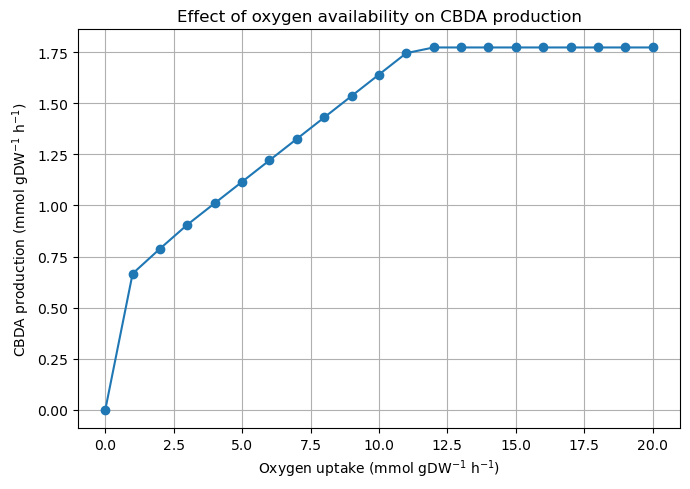

In [23]:
plt.figure(figsize=(7,5))

plt.plot(oxygen_rates, cbda_fluxes, marker='o')

plt.xlabel("Oxygen uptake (mmol gDW$^{-1}$ h$^{-1}$)")
plt.ylabel("CBDA production (mmol gDW$^{-1}$ h$^{-1}$)")
plt.title("Effect of oxygen availability on CBDA production")

plt.grid(True)

plt.tight_layout()

plt.savefig("figures/oxygen_sensitivity.png", dpi=300)

plt.show()